In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.datasets import load_wine, fetch_california_housing
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, mean_absolute_error, r2_score, mean_squared_error
from sklearn.decomposition import PCA
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from scipy.cluster.hierarchy import linkage, dendrogram

keras = tf.keras
layers = tf.keras.layers

X = load_wine(as_frame=True).data
print(X.head())
print("Hajmi:", X.shape)

I0000 00:00:1795629642.994308   76292 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


   alcohol  malic_acid   ash  alcalinity_of_ash  magnesium  total_phenols  \
0    14.23        1.71  2.43               15.6      127.0           2.80   
1    13.20        1.78  2.14               11.2      100.0           2.65   
2    13.16        2.36  2.67               18.6      101.0           2.80   
3    14.37        1.95  2.50               16.8      113.0           3.85   
4    13.24        2.59  2.87               21.0      118.0           2.80   

   flavanoids  nonflavanoid_phenols  proanthocyanins  color_intensity   hue  \
0        3.06                  0.28             2.29             5.64  1.04   
1        2.76                  0.26             1.28             4.38  1.05   
2        3.24                  0.30             2.81             5.68  1.03   
3        3.49                  0.24             2.18             7.80  0.86   
4        2.69                  0.39             1.82             4.32  1.04   

   od280/od315_of_diluted_wines  proline  
0                  

K=2  silhouette=0.268
K=3  silhouette=0.285
K=4  silhouette=0.252


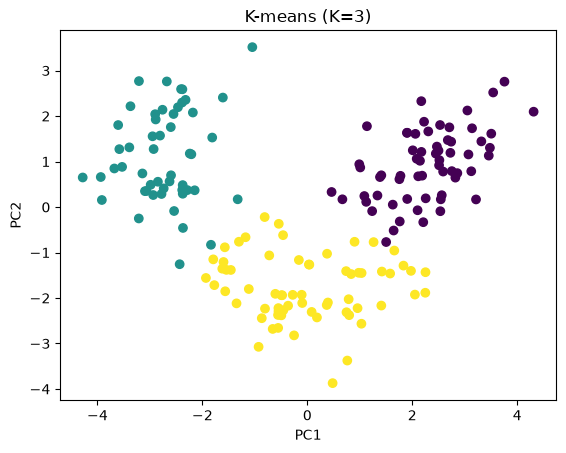

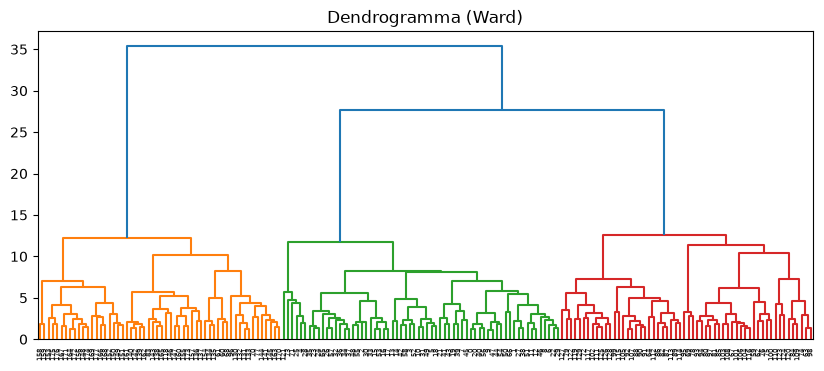

Ierarxik silhouette: 0.277
       Usul  Klasterlar soni  Silhouette
0   K-means                3    0.284859
1  Ierarxik                3    0.277444


In [8]:
Xs = StandardScaler().fit_transform(X)

scores = {}
for k in [2, 3, 4]:
    labels = KMeans(n_clusters=k, n_init=10, random_state=24).fit_predict(Xs)
    scores[k] = silhouette_score(Xs, labels)
    print(f"K={k}  silhouette={scores[k]:.3f}")

best_k = max(scores, key=scores.get)
km_labels = KMeans(n_clusters=best_k, n_init=10, random_state=24).fit_predict(Xs)
X2 = PCA(n_components=2).fit_transform(Xs)

plt.scatter(X2[:, 0], X2[:, 1], c=km_labels, cmap="viridis")
plt.title(f"K-means (K={best_k})")
plt.xlabel("PC1"); plt.ylabel("PC2")
plt.show()

plt.figure(figsize=(10, 4))
dendrogram(linkage(Xs, method="ward"))
plt.title("Dendrogramma (Ward)")
plt.show()

hc_labels = AgglomerativeClustering(n_clusters=best_k).fit_predict(Xs)
print("Ierarxik silhouette:", round(silhouette_score(Xs, hc_labels), 3))

print(pd.DataFrame({
    "Usul": ["K-means", "Ierarxik"],
    "Klasterlar soni": [best_k, best_k],
    "Silhouette": [silhouette_score(Xs, km_labels), silhouette_score(Xs, hc_labels)]
}))

/home/temur/Documents/vs_da/work/Data-science/venv/lib/python3.14/site-packages/keras/src/layers/core/dense.py:97: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
W0000 00:00:1795629645.900846   77382 cuda_executor.cc:1710] Failed to determine cuDNN version (Note that this is expected if the application doesn't link the cuDNN plugin): INTERNAL: cuDNN error: CUDNN_STATUS_INTERNAL_ERROR
=== Source Location Trace: ===
external/xla/xla/stream_executor/cuda/cudnn_api_wrappers.cc:77
external/xla/xla/stream_executor/cuda/cudnn_api_wrappers.cc:107
external/xla/xla/stream_executor/cuda/cudnn_api_wrappers.cc:112

W0000 00:00:1795629645.972334   76292 dlopen_checker.cc:38] Could not load dynamic library 'libcudnn.so.9'; dlerror: libcudnn.so.9: cannot open shared object file: No such file or d

16 neyron: accuracy = 0.8950
32 neyron: accuracy = 0.9100


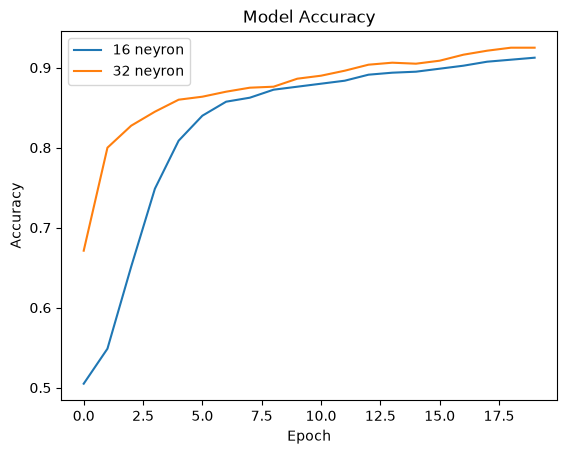

In [9]:
X, y = make_classification(n_samples=1000, n_features=10,
                          n_informative=6, random_state=24)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=24
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

for h in [16, 32]:
    model = keras.Sequential([
        layers.Dense(h, activation="relu", input_shape=(10,)),
        layers.Dense(16, activation="relu"),
        layers.Dense(1, activation="sigmoid")
    ])

    model.compile(optimizer="adam",
                  loss="binary_crossentropy",
                  metrics=["accuracy"])

    hist = model.fit(X_train, y_train, epochs=20,
                     batch_size=32, verbose=0)

    loss, acc = model.evaluate(X_test, y_test, verbose=0)

    print(f"{h} neyron: accuracy = {acc:.4f}")

    plt.plot(hist.history["accuracy"], label=f"{h} neyron")

plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

/home/temur/Documents/vs_da/work/Data-science/venv/lib/python3.14/site-packages/keras/src/layers/core/dense.py:97: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


129/129 ━━━━━━━━━━━━━━━━━━━━ 0s 460us/step
MAE : 0.3733675651749368
RMSE: 0.5512103260922122
R2  : 0.7707026409443034


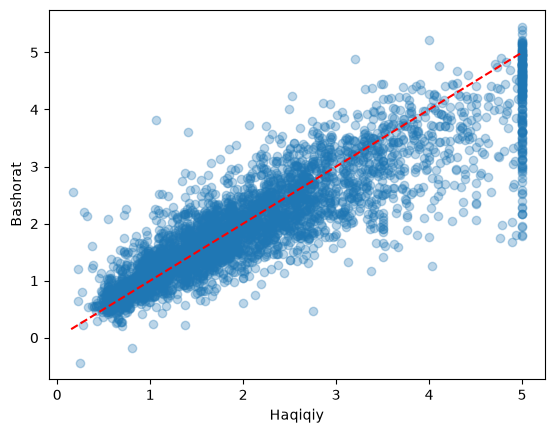

In [10]:
data = fetch_california_housing(as_frame=True)
X, y = data.data, data.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=24
)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

model = keras.Sequential([
    layers.Dense(32, activation="relu", input_shape=(8,)),
    layers.Dense(16, activation="relu"),
    layers.Dense(1)
])

model.compile(optimizer="adam", loss="mse")
model.fit(X_train, y_train, epochs=30, verbose=0)

y_pred = model.predict(X_test).flatten()

print("MAE :", mean_absolute_error(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("R2  :", r2_score(y_test, y_pred))

plt.scatter(y_test, y_pred, alpha=0.3)
plt.plot([y.min(), y.max()], [y.min(), y.max()], "r--")
plt.xlabel("Haqiqiy")
plt.ylabel("Bashorat")
plt.show()